In [1]:
import os
import random
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models, applications, optimizers, callbacks
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score, precision_score, recall_score

# ===========================================================
# 0. FIX RANDOM SEEDS FOR REPRODUCIBILITY
# ===========================================================
SEED = 123
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ===========================================================
# 1. DATASET SETUP
# ===========================================================
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
DATA_DIR = r"Downloads/kvasir-dataset-v2/kvasir-dataset-v2"  # Update with your absolute dataset path

# Load dataset with a fixed split.
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.3,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)

# IMPORTANT: Folder name must exactly match – for example, if merged folder is named "Normal"
normal_index = class_names.index("Normal")
print("Normal class index:", normal_index)

# ===========================================================
# 2. PREPROCESSING FUNCTIONS
# ===========================================================

# --- Baseline: No advanced enhancement ---
# In the baseline pipeline we simply normalize and apply augmentation.

# --- Enhanced: Use CLAHE-only enhancement (tuned) ---
def preprocess_image_clahe(image):
    """
    Process a NumPy RGB image:
      - Force 3 channels.
      - Convert to LAB, apply CLAHE on L channel with clipLimit=3.0 and tileGridSize=(8,8).
      - Convert back to RGB.
    (Note: Black Hat is removed.)
    """
    # Ensure image has 3 channels.
    if image.ndim == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
    elif image.ndim == 3:
        if image.shape[-1] == 1:
            image = np.concatenate([image, image, image], axis=-1)
        elif image.shape[-1] == 4:
            image = cv2.cvtColor(image, cv2.COLOR_RGBA2RGB)
        elif image.shape[-1] != 3:
            image = image[..., :3]
    
    # Convert from RGB to LAB.
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    # Apply CLAHE with tuned parameters.
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    l_clahe = clahe.apply(l)
    lab_enhanced = cv2.merge([l_clahe, a, b])
    image_enhanced = cv2.cvtColor(lab_enhanced, cv2.COLOR_LAB2RGB)
    return image_enhanced

def tf_preprocess_image_enhanced(image):
    """
    TensorFlow wrapper for CLAHE-only enhancement.
    Processes a single image or a batch using tf.map_fn.
    """
    def _process_single(img):
        arr = np.array(img, dtype=np.uint8)
        processed = preprocess_image_clahe(arr)
        return processed
    
    if len(image.shape) == 4:
        processed = tf.map_fn(
            lambda x: tf.py_function(func=_process_single, inp=[x], Tout=tf.uint8),
            image, fn_output_signature=tf.uint8
        )
    else:
        processed = tf.py_function(func=_process_single, inp=[image], Tout=tf.uint8)
    processed.set_shape(image.shape)
    return processed

# ===========================================================
# 3. CLASS-SPECIFIC AUGMENTATION FUNCTIONS
# ===========================================================
def augment_single_sample(img, lbl):
    """
    For a single image-label pair:
      - If label equals normal_index: apply random brightness.
      - Otherwise: apply horizontal flip, 180° rotation, and random brightness.
    """
    def normal_aug():
        return tf.image.random_brightness(img, max_delta=0.1)
    def non_normal_aug():
        aug_img = tf.image.flip_left_right(img)
        aug_img = tf.image.rot90(aug_img, k=2)
        aug_img = tf.image.random_brightness(aug_img, max_delta=0.1)
        return aug_img
    augmented_img = tf.cond(tf.equal(lbl, normal_index),
                            lambda: normal_aug(),
                            lambda: non_normal_aug())
    return augmented_img, lbl

def custom_augmentation_batch(images, labels):
    """
    Apply augment_single_sample element-wise over a batch using tf.map_fn.
    """
    augmented_images, new_labels = tf.map_fn(
        lambda x: augment_single_sample(x[0], x[1]),
        (images, labels),
        fn_output_signature=(tf.float32, labels.dtype)
    )
    return augmented_images, new_labels

# ===========================================================
# 4. PIPELINE FUNCTIONS
# ===========================================================
def preprocess_baseline(images, labels):
    """
    Baseline pipeline: Normalize images to [0,1] and apply class-specific augmentation.
    """
    images = tf.cast(images, tf.float32) / 255.0
    images, labels = custom_augmentation_batch(images, labels)
    return images, labels

def preprocess_enhanced(images, labels):
    """
    Enhanced pipeline:
      - Apply CLAHE-only enhancement.
      - Normalize images to [0,1].
      - Apply class-specific augmentation.
    """
    images = tf_preprocess_image_enhanced(images)
    images = tf.cast(images, tf.float32) / 255.0
    images, labels = custom_augmentation_batch(images, labels)
    return images, labels

# Map the pipelines.
baseline_train_ds = train_ds.map(preprocess_baseline, num_parallel_calls=tf.data.AUTOTUNE)
baseline_val_ds   = val_ds.map(preprocess_baseline, num_parallel_calls=tf.data.AUTOTUNE)
enhanced_train_ds = train_ds.map(preprocess_enhanced, num_parallel_calls=tf.data.AUTOTUNE)
enhanced_val_ds   = val_ds.map(preprocess_enhanced, num_parallel_calls=tf.data.AUTOTUNE)

baseline_train_ds = baseline_train_ds.prefetch(tf.data.AUTOTUNE)
baseline_val_ds   = baseline_val_ds.prefetch(tf.data.AUTOTUNE)
enhanced_train_ds = enhanced_train_ds.prefetch(tf.data.AUTOTUNE)
enhanced_val_ds   = enhanced_val_ds.prefetch(tf.data.AUTOTUNE)

# ===========================================================
# 5. SAC MODEL (Spatial-Attention ConvMixer)
# ===========================================================
def cbam_block(input_tensor, reduction_ratio=16):
    channel = input_tensor.shape[-1]
    
    # Channel Attention Module.
    avg_pool = layers.GlobalAveragePooling2D()(input_tensor)
    avg_pool = layers.Reshape((1, 1, channel))(avg_pool)
    avg_pool = layers.Dense(channel // reduction_ratio, activation='relu', kernel_initializer='he_normal', use_bias=True)(avg_pool)
    avg_pool = layers.Dense(channel, kernel_initializer='he_normal', use_bias=True)(avg_pool)
    
    max_pool = layers.GlobalMaxPooling2D()(input_tensor)
    max_pool = layers.Reshape((1, 1, channel))(max_pool)
    max_pool = layers.Dense(channel // reduction_ratio, activation='relu', kernel_initializer='he_normal', use_bias=True)(max_pool)
    max_pool = layers.Dense(channel, kernel_initializer='he_normal', use_bias=True)(max_pool)
    
    channel_attention = layers.Add()([avg_pool, max_pool])
    channel_attention = layers.Activation('sigmoid')(channel_attention)
    channel_refined = layers.Multiply()([input_tensor, channel_attention])
    
    # Spatial Attention Module.
    avg_pool_spatial = layers.Lambda(lambda x: tf.reduce_mean(x, axis=-1, keepdims=True))(channel_refined)
    max_pool_spatial = layers.Lambda(lambda x: tf.reduce_max(x, axis=-1, keepdims=True))(channel_refined)
    concat = layers.Concatenate(axis=-1)([avg_pool_spatial, max_pool_spatial])
    spatial_attention = layers.Conv2D(filters=1, kernel_size=7, strides=1, padding='same',
                                      activation='sigmoid', kernel_initializer='he_normal', use_bias=False)(concat)
    refined_feature = layers.Multiply()([channel_refined, spatial_attention])
    return refined_feature

def build_model(num_classes):
    base_model = applications.EfficientNetB0(include_top=False, input_shape=IMG_SIZE + (3,), weights='imagenet')
    base_model.trainable = True  # Fine-tune all layers
    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = base_model(inputs, training=True)
    x = cbam_block(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model = models.Model(inputs, outputs)
    return model

print("Number of classes:", num_classes)
model = build_model(num_classes)
model.summary()

# ===========================================================
# 6. TRAINING & EVALUATION FUNCTIONS
# ===========================================================
def compile_and_train(model, train_ds, val_ds, experiment_name, epochs=25, lr=0.001):
    model.compile(optimizer=optimizers.AdamW(learning_rate=lr, weight_decay=0.0001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    lr_callback = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
    checkpoint_callback = callbacks.ModelCheckpoint(f"{experiment_name}_best_model.h5", monitor='val_accuracy',
                                                      save_best_only=True, verbose=1)
    history = model.fit(train_ds,
                        validation_data=val_ds,
                        epochs=epochs,
                        callbacks=[lr_callback, checkpoint_callback])
    return history

def evaluate_model(model, dataset, class_names):
    y_true = []
    y_pred = []
    for images, labels in dataset:
        preds = model.predict(images)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(preds, axis=1))
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted')
    prec = precision_score(y_true, y_pred, average='weighted')
    rec = recall_score(y_true, y_pred, average='weighted')
    conf_mat = confusion_matrix(y_true, y_pred)
    cls_report = classification_report(y_true, y_pred, target_names=class_names)
    print(f"Accuracy:  {acc:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print("Confusion Matrix:\n", conf_mat)
    print("\nClassification Report:\n", cls_report)

# ===========================================================
# 7. VISUALIZATION FUNCTIONS
# ===========================================================
def plot_training_curves(history, title_prefix="Model"):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))
    
    plt.figure(figsize=(14,5))
    plt.subplot(1,2,1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.title(f"{title_prefix} Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend(loc='lower right')
    
    plt.subplot(1,2,2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.title(f"{title_prefix} Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend(loc='upper right')
    plt.show()

def plot_confusion_matrix(cm, class_names, title="Confusion Matrix"):
    fig, ax = plt.subplots(figsize=(8,6))
    cax = ax.matshow(cm, cmap=plt.cm.Blues)
    fig.colorbar(cax)
    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha='left')
    ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.set_title(title, pad=20)
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j, i, str(cm[i, j]), va='center', ha='center', color='red', fontsize=12)
    plt.show()



Found 8001 files belonging to 6 classes.
Using 5601 files for training.
Found 8001 files belonging to 6 classes.
Using 2400 files for validation.
Classes: ['Dyed-lifted-polyps', 'Dyed-resection-margins', 'Esophagitis', 'Normal', 'Polyps', 'Ulcerative-colitis']
Normal class index: 3
Number of classes: 6



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 128, 128, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ efficientnetb0 (Functional)   │ (None, 4, 4, 1280)        │       4,049,571 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 1280)              │               0 │ efficientnetb0[0][0]       │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_max_pooling2d          │ (None, 1280)              │               0 │ efficientnetb0[0][0]       │
│ (GlobalMaxPooling2D)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape (Reshape)             │ (None, 1, 1, 1280)        │               0 │ global_average_pooling2d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ reshape_1 (Reshape)           │ (None, 1, 1, 1280)        │               0 │ global_max_pooling2d[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 1, 1, 80)          │         102,480 │ reshape[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_2 (Dense)               │ (None, 1, 1, 80)          │         102,480 │ reshape_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 1, 1, 1280)        │         103,680 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_3 (Dense)               │ (None, 1, 1, 1280)        │         103,680 │ dense_2[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 1, 1, 1280)        │               0 │ dense_1[0][0],             │
│                               │                           │                 │ dense_3[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 1, 1, 1280)        │               0 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multiply (Multiply)           │ (None, 4, 4, 1280)        │               0 │ efficientnetb0[0][0],      │
│                               │                           │                 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lambda (Lambda)               │ (None, 4, 4, 1)           │               0 │ multiply[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lambda_1 (Lambda)             │ (None, 4, 4, 1)           │               0 │ multiply[0][0]             │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 4,469,675 (17.05 MB)

 Trainable params: 4,427,652 (16.89 MB)

 Non-trainable params: 42,023 (164.16 KB)


=== Training SAC Model with Baseline Preprocessing ===
Epoch 1/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 711ms/step - accuracy: 0.7402 - loss: 0.6927
Epoch 1: val_accuracy improved from -inf to 0.12625, saving model to SAC_baseline_best_model.h5


176/176 ━━━━━━━━━━━━━━━━━━━━ 175s 794ms/step - accuracy: 0.7409 - loss: 0.6912 - val_accuracy: 0.1262 - val_loss: 2.6668 - learning_rate: 0.0010
Epoch 2/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 667ms/step - accuracy: 0.9332 - loss: 0.1953
Epoch 2: val_accuracy did not improve from 0.12625
176/176 ━━━━━━━━━━━━━━━━━━━━ 130s 739ms/step - accuracy: 0.9333 - loss: 0.1952 - val_accuracy: 0.1262 - val_loss: 5.2591 - learning_rate: 0.0010
Epoch 3/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 638ms/step - accuracy: 0.9543 - loss: 0.1306
Epoch 3: val_accuracy improved from 0.12625 to 0.15375, saving model to SAC_baseline_best_model.h5


176/176 ━━━━━━━━━━━━━━━━━━━━ 126s 710ms/step - accuracy: 0.9543 - loss: 0.1305 - val_accuracy: 0.1538 - val_loss: 2.2963 - learning_rate: 0.0010
Epoch 4/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 598ms/step - accuracy: 0.9728 - loss: 0.0797
Epoch 4: val_accuracy improved from 0.15375 to 0.17833, saving model to SAC_baseline_best_model.h5


176/176 ━━━━━━━━━━━━━━━━━━━━ 117s 661ms/step - accuracy: 0.9728 - loss: 0.0797 - val_accuracy: 0.1783 - val_loss: 2.3075 - learning_rate: 0.0010
Epoch 5/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 590ms/step - accuracy: 0.9800 - loss: 0.0687
Epoch 5: val_accuracy did not improve from 0.17833
176/176 ━━━━━━━━━━━━━━━━━━━━ 115s 649ms/step - accuracy: 0.9800 - loss: 0.0687 - val_accuracy: 0.1596 - val_loss: 2.1295 - learning_rate: 0.0010
Epoch 6/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 596ms/step - accuracy: 0.9760 - loss: 0.0629
Epoch 6: val_accuracy did not improve from 0.17833
176/176 ━━━━━━━━━━━━━━━━━━━━ 116s 659ms/step - accuracy: 0.9761 - loss: 0.0629 - val_accuracy: 0.1262 - val_loss: 5.1287 - learning_rate: 0.0010
Epoch 7/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 585ms/step - accuracy: 0.9691 - loss: 0.0896
Epoch 7: val_accuracy did not improve from 0.17833
176/176 ━━━━━━━━━━━━━━━━━━━━ 114s 646ms/step - accuracy: 0.9691 - loss: 0.0896 - val_accuracy: 0.1338 - val_loss: 3.4485 - learning_rate: 0.0010
Epo

176/176 ━━━━━━━━━━━━━━━━━━━━ 114s 643ms/step - accuracy: 0.9865 - loss: 0.0376 - val_accuracy: 0.3408 - val_loss: 1.9053 - learning_rate: 0.0010
Epoch 9/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.9872 - loss: 0.0408
Epoch 9: val_accuracy did not improve from 0.34083
176/176 ━━━━━━━━━━━━━━━━━━━━ 98s 553ms/step - accuracy: 0.9872 - loss: 0.0408 - val_accuracy: 0.3042 - val_loss: 1.8976 - learning_rate: 0.0010
Epoch 10/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.9650 - loss: 0.1168
Epoch 10: val_accuracy did not improve from 0.34083
176/176 ━━━━━━━━━━━━━━━━━━━━ 97s 551ms/step - accuracy: 0.9651 - loss: 0.1166 - val_accuracy: 0.1262 - val_loss: 3.0848 - learning_rate: 0.0010
Epoch 11/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 526ms/step - accuracy: 0.9842 - loss: 0.0504
Epoch 11: val_accuracy improved from 0.34083 to 0.38625, saving model to SAC_baseline_best_model.h5


176/176 ━━━━━━━━━━━━━━━━━━━━ 102s 577ms/step - accuracy: 0.9842 - loss: 0.0504 - val_accuracy: 0.3862 - val_loss: 2.2105 - learning_rate: 0.0010
Epoch 12/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 541ms/step - accuracy: 0.9874 - loss: 0.0417
Epoch 12: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 12: val_accuracy improved from 0.38625 to 0.44042, saving model to SAC_baseline_best_model.h5


176/176 ━━━━━━━━━━━━━━━━━━━━ 104s 590ms/step - accuracy: 0.9874 - loss: 0.0417 - val_accuracy: 0.4404 - val_loss: 2.1015 - learning_rate: 0.0010
Epoch 13/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 521ms/step - accuracy: 0.9964 - loss: 0.0151
Epoch 13: val_accuracy improved from 0.44042 to 0.78917, saving model to SAC_baseline_best_model.h5


176/176 ━━━━━━━━━━━━━━━━━━━━ 101s 570ms/step - accuracy: 0.9964 - loss: 0.0151 - val_accuracy: 0.7892 - val_loss: 0.6034 - learning_rate: 5.0000e-04
Epoch 14/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - accuracy: 0.9981 - loss: 0.0066
Epoch 14: val_accuracy did not improve from 0.78917
176/176 ━━━━━━━━━━━━━━━━━━━━ 101s 571ms/step - accuracy: 0.9980 - loss: 0.0066 - val_accuracy: 0.5646 - val_loss: 1.8507 - learning_rate: 5.0000e-04
Epoch 15/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 535ms/step - accuracy: 0.9941 - loss: 0.0167
Epoch 15: val_accuracy did not improve from 0.78917
176/176 ━━━━━━━━━━━━━━━━━━━━ 102s 580ms/step - accuracy: 0.9941 - loss: 0.0167 - val_accuracy: 0.2433 - val_loss: 2.6906 - learning_rate: 5.0000e-04
Epoch 16/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 513ms/step - accuracy: 0.9961 - loss: 0.0110
Epoch 16: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 16: val_accuracy did not improve from 0.78917
176/176 ━━━━━━━━━━━━━━━━━━━━ 98s 557ms/step - accura

176/176 ━━━━━━━━━━━━━━━━━━━━ 97s 548ms/step - accuracy: 0.9985 - loss: 0.0051 - val_accuracy: 0.8579 - val_loss: 0.5072 - learning_rate: 2.5000e-04
Epoch 18/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 499ms/step - accuracy: 0.9987 - loss: 0.0038
Epoch 18: val_accuracy did not improve from 0.85792
176/176 ━━━━━━━━━━━━━━━━━━━━ 96s 543ms/step - accuracy: 0.9987 - loss: 0.0038 - val_accuracy: 0.3267 - val_loss: 4.2768 - learning_rate: 2.5000e-04
Epoch 19/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - accuracy: 0.9997 - loss: 0.0025
Epoch 19: val_accuracy improved from 0.85792 to 0.88583, saving model to SAC_baseline_best_model.h5


176/176 ━━━━━━━━━━━━━━━━━━━━ 96s 545ms/step - accuracy: 0.9997 - loss: 0.0025 - val_accuracy: 0.8858 - val_loss: 0.3658 - learning_rate: 2.5000e-04
Epoch 20/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 501ms/step - accuracy: 0.9987 - loss: 0.0033
Epoch 20: val_accuracy did not improve from 0.88583
176/176 ━━━━━━━━━━━━━━━━━━━━ 96s 544ms/step - accuracy: 0.9987 - loss: 0.0033 - val_accuracy: 0.6871 - val_loss: 0.9178 - learning_rate: 2.5000e-04
Epoch 21/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 511ms/step - accuracy: 0.9983 - loss: 0.0045
Epoch 21: val_accuracy did not improve from 0.88583
176/176 ━━━━━━━━━━━━━━━━━━━━ 98s 555ms/step - accuracy: 0.9983 - loss: 0.0045 - val_accuracy: 0.7946 - val_loss: 0.6840 - learning_rate: 2.5000e-04
Epoch 22/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 512ms/step - accuracy: 0.9989 - loss: 0.0045
Epoch 22: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 22: val_accuracy did not improve from 0.88583
176/176 ━━━━━━━━━━━━━━━━━━━━ 98s 557ms/step - accuracy:

176/176 ━━━━━━━━━━━━━━━━━━━━ 98s 557ms/step - accuracy: 0.9999 - loss: 0.0011 - val_accuracy: 0.9467 - val_loss: 0.2165 - learning_rate: 1.2500e-04
Epoch 24/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 509ms/step - accuracy: 0.9996 - loss: 0.0023
Epoch 24: val_accuracy did not improve from 0.94667
176/176 ━━━━━━━━━━━━━━━━━━━━ 98s 553ms/step - accuracy: 0.9996 - loss: 0.0023 - val_accuracy: 0.9308 - val_loss: 0.2851 - learning_rate: 1.2500e-04
Epoch 25/25
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 509ms/step - accuracy: 0.9995 - loss: 0.0013
Epoch 25: val_accuracy did not improve from 0.94667
176/176 ━━━━━━━━━━━━━━━━━━━━ 98s 554ms/step - accuracy: 0.9995 - loss: 0.0013 - val_accuracy: 0.9367 - val_loss: 0.3031 - learning_rate: 1.2500e-04

=== Baseline SAC Model Evaluation ===
75/75 ━━━━━━━━━━━━━━━━━━━━ 8s 104ms/step - accuracy: 0.9374 - loss: 0.2921
Baseline SAC Val Loss: 0.3006 | Baseline SAC Val Accuracy: 0.9367
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━

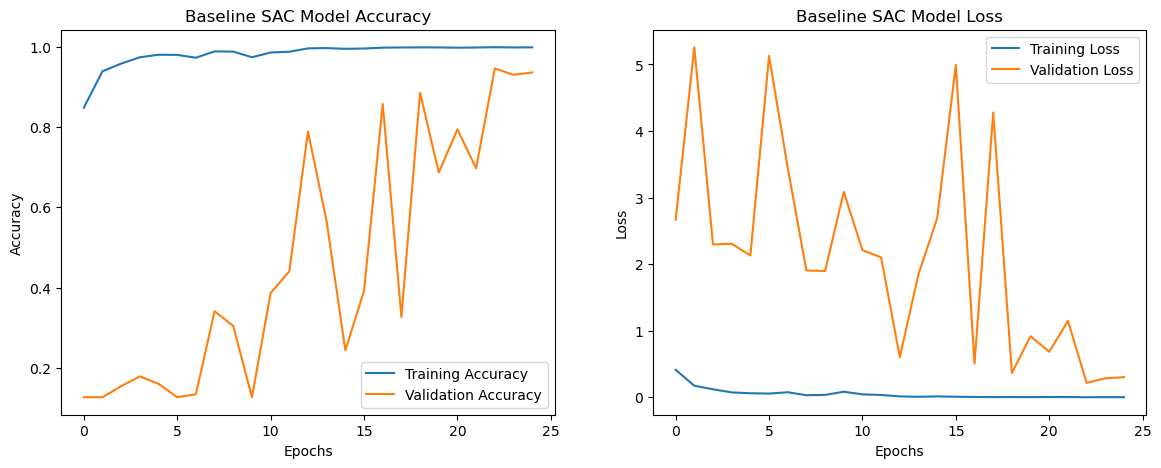


=== Training SAC Model with Enhanced Preprocessing ===
Epoch 1/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 575ms/step - accuracy: 0.7250 - loss: 0.7410
Epoch 1: val_accuracy improved from -inf to 0.37375, saving model to SAC_enhanced_best_model.h5


176/176 ━━━━━━━━━━━━━━━━━━━━ 143s 644ms/step - accuracy: 0.7256 - loss: 0.7393 - val_accuracy: 0.3738 - val_loss: 1.7642 - learning_rate: 8.0000e-04
Epoch 2/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 556ms/step - accuracy: 0.9413 - loss: 0.1857
Epoch 2: val_accuracy improved from 0.37375 to 0.39542, saving model to SAC_enhanced_best_model.h5


176/176 ━━━━━━━━━━━━━━━━━━━━ 108s 613ms/step - accuracy: 0.9413 - loss: 0.1857 - val_accuracy: 0.3954 - val_loss: 1.9122 - learning_rate: 8.0000e-04
Epoch 3/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 559ms/step - accuracy: 0.9558 - loss: 0.1323
Epoch 3: val_accuracy did not improve from 0.39542
176/176 ━━━━━━━━━━━━━━━━━━━━ 109s 615ms/step - accuracy: 0.9559 - loss: 0.1323 - val_accuracy: 0.3738 - val_loss: 3.2577 - learning_rate: 8.0000e-04
Epoch 4/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 555ms/step - accuracy: 0.9693 - loss: 0.1015
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.00039999998989515007.

Epoch 4: val_accuracy did not improve from 0.39542
176/176 ━━━━━━━━━━━━━━━━━━━━ 108s 611ms/step - accuracy: 0.9693 - loss: 0.1014 - val_accuracy: 0.3008 - val_loss: 2.6428 - learning_rate: 8.0000e-04
Epoch 5/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 555ms/step - accuracy: 0.9832 - loss: 0.0499
Epoch 5: val_accuracy did not improve from 0.39542
176/176 ━━━━━━━━━━━━━━━━━━━━ 108s 610ms/step - accuracy: 0

176/176 ━━━━━━━━━━━━━━━━━━━━ 108s 612ms/step - accuracy: 0.9951 - loss: 0.0195 - val_accuracy: 0.4225 - val_loss: 1.9535 - learning_rate: 4.0000e-04
Epoch 8/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - accuracy: 0.9946 - loss: 0.0134
Epoch 8: val_accuracy improved from 0.42250 to 0.88375, saving model to SAC_enhanced_best_model.h5


176/176 ━━━━━━━━━━━━━━━━━━━━ 109s 617ms/step - accuracy: 0.9946 - loss: 0.0134 - val_accuracy: 0.8838 - val_loss: 0.3931 - learning_rate: 2.0000e-04
Epoch 9/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 549ms/step - accuracy: 0.9969 - loss: 0.0101
Epoch 9: val_accuracy did not improve from 0.88375
176/176 ━━━━━━━━━━━━━━━━━━━━ 106s 602ms/step - accuracy: 0.9969 - loss: 0.0102 - val_accuracy: 0.7117 - val_loss: 0.8979 - learning_rate: 2.0000e-04
Epoch 10/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 549ms/step - accuracy: 0.9970 - loss: 0.0095
Epoch 10: val_accuracy did not improve from 0.88375
176/176 ━━━━━━━━━━━━━━━━━━━━ 106s 603ms/step - accuracy: 0.9970 - loss: 0.0095 - val_accuracy: 0.5888 - val_loss: 1.4022 - learning_rate: 2.0000e-04
Epoch 11/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 543ms/step - accuracy: 0.9984 - loss: 0.0068
Epoch 11: ReduceLROnPlateau reducing learning rate to 9.999999747378752e-05.

Epoch 11: val_accuracy did not improve from 0.88375
176/176 ━━━━━━━━━━━━━━━━━━━━ 105s 595ms/step - accurac

176/176 ━━━━━━━━━━━━━━━━━━━━ 106s 602ms/step - accuracy: 0.9973 - loss: 0.0107 - val_accuracy: 0.9542 - val_loss: 0.1718 - learning_rate: 1.0000e-04
Epoch 13/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 550ms/step - accuracy: 0.9996 - loss: 0.0031
Epoch 13: val_accuracy did not improve from 0.95417
176/176 ━━━━━━━━━━━━━━━━━━━━ 107s 605ms/step - accuracy: 0.9996 - loss: 0.0031 - val_accuracy: 0.9529 - val_loss: 0.1803 - learning_rate: 1.0000e-04
Epoch 14/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 547ms/step - accuracy: 0.9994 - loss: 0.0028
Epoch 14: val_accuracy did not improve from 0.95417
176/176 ━━━━━━━━━━━━━━━━━━━━ 106s 600ms/step - accuracy: 0.9993 - loss: 0.0028 - val_accuracy: 0.8971 - val_loss: 0.3524 - learning_rate: 1.0000e-04
Epoch 15/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 548ms/step - accuracy: 0.9995 - loss: 0.0024
Epoch 15: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.

Epoch 15: val_accuracy did not improve from 0.95417
176/176 ━━━━━━━━━━━━━━━━━━━━ 106s 602ms/step - accur

176/176 ━━━━━━━━━━━━━━━━━━━━ 105s 596ms/step - accuracy: 0.9999 - loss: 0.0014 - val_accuracy: 0.9600 - val_loss: 0.1702 - learning_rate: 5.0000e-05
Epoch 17/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 539ms/step - accuracy: 0.9998 - loss: 0.0017
Epoch 17: val_accuracy did not improve from 0.96000
176/176 ━━━━━━━━━━━━━━━━━━━━ 104s 591ms/step - accuracy: 0.9998 - loss: 0.0017 - val_accuracy: 0.9554 - val_loss: 0.1979 - learning_rate: 5.0000e-05
Epoch 18/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 545ms/step - accuracy: 0.9985 - loss: 0.0028
Epoch 18: val_accuracy did not improve from 0.96000
176/176 ━━━━━━━━━━━━━━━━━━━━ 106s 599ms/step - accuracy: 0.9985 - loss: 0.0028 - val_accuracy: 0.9533 - val_loss: 0.1904 - learning_rate: 5.0000e-05
Epoch 19/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 1.0000 - loss: 0.0021
Epoch 19: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.

Epoch 19: val_accuracy did not improve from 0.96000
176/176 ━━━━━━━━━━━━━━━━━━━━ 105s 596ms/step - accur

176/176 ━━━━━━━━━━━━━━━━━━━━ 106s 598ms/step - accuracy: 0.9995 - loss: 0.0021 - val_accuracy: 0.9621 - val_loss: 0.1626 - learning_rate: 2.5000e-05
Epoch 21/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 0.9996 - loss: 0.0021
Epoch 21: val_accuracy did not improve from 0.96208
176/176 ━━━━━━━━━━━━━━━━━━━━ 105s 597ms/step - accuracy: 0.9996 - loss: 0.0021 - val_accuracy: 0.9608 - val_loss: 0.1871 - learning_rate: 2.5000e-05
Epoch 22/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 0.9997 - loss: 0.0017
Epoch 22: val_accuracy improved from 0.96208 to 0.96250, saving model to SAC_enhanced_best_model.h5


176/176 ━━━━━━━━━━━━━━━━━━━━ 106s 600ms/step - accuracy: 0.9997 - loss: 0.0017 - val_accuracy: 0.9625 - val_loss: 0.1643 - learning_rate: 2.5000e-05
Epoch 23/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 544ms/step - accuracy: 0.9997 - loss: 0.0014
Epoch 23: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-05.

Epoch 23: val_accuracy did not improve from 0.96250
176/176 ━━━━━━━━━━━━━━━━━━━━ 105s 597ms/step - accuracy: 0.9997 - loss: 0.0014 - val_accuracy: 0.9608 - val_loss: 0.1793 - learning_rate: 2.5000e-05
Epoch 24/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 545ms/step - accuracy: 0.9997 - loss: 0.0014
Epoch 24: val_accuracy did not improve from 0.96250
176/176 ━━━━━━━━━━━━━━━━━━━━ 106s 600ms/step - accuracy: 0.9997 - loss: 0.0014 - val_accuracy: 0.9596 - val_loss: 0.1683 - learning_rate: 1.2500e-05
Epoch 25/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 537ms/step - accuracy: 0.9994 - loss: 0.0019
Epoch 25: val_accuracy did not improve from 0.96250
176/176 ━━━━━━━━━━━━━━━━━━━━ 104s 589ms/step - accur

176/176 ━━━━━━━━━━━━━━━━━━━━ 105s 594ms/step - accuracy: 0.9995 - loss: 0.0014 - val_accuracy: 0.9629 - val_loss: 0.1634 - learning_rate: 3.1250e-06

=== Enhanced SAC Model Evaluation ===
75/75 ━━━━━━━━━━━━━━━━━━━━ 9s 120ms/step - accuracy: 0.9626 - loss: 0.1607
Enhanced SAC Val Loss: 0.1637 | Enhanced SAC Val Accuracy: 0.9604
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━

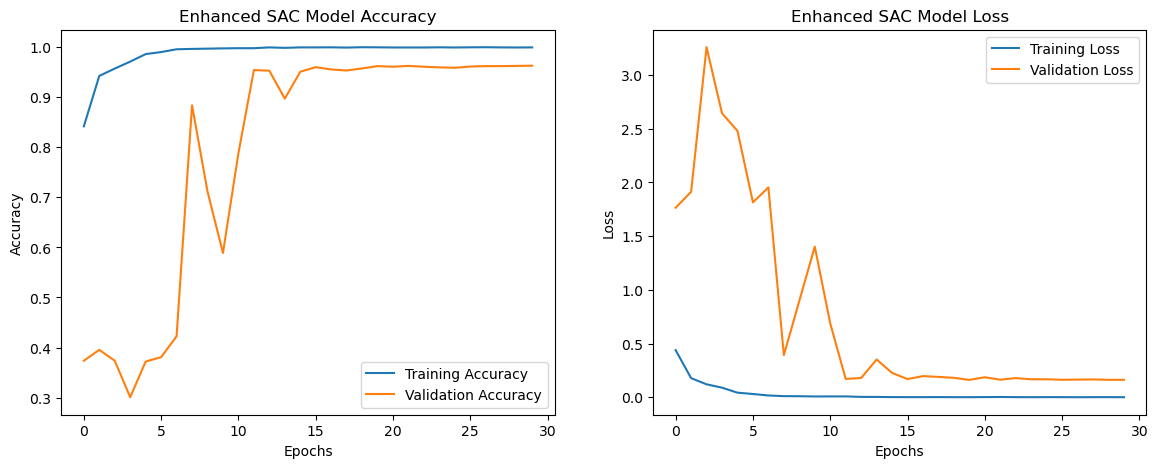

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

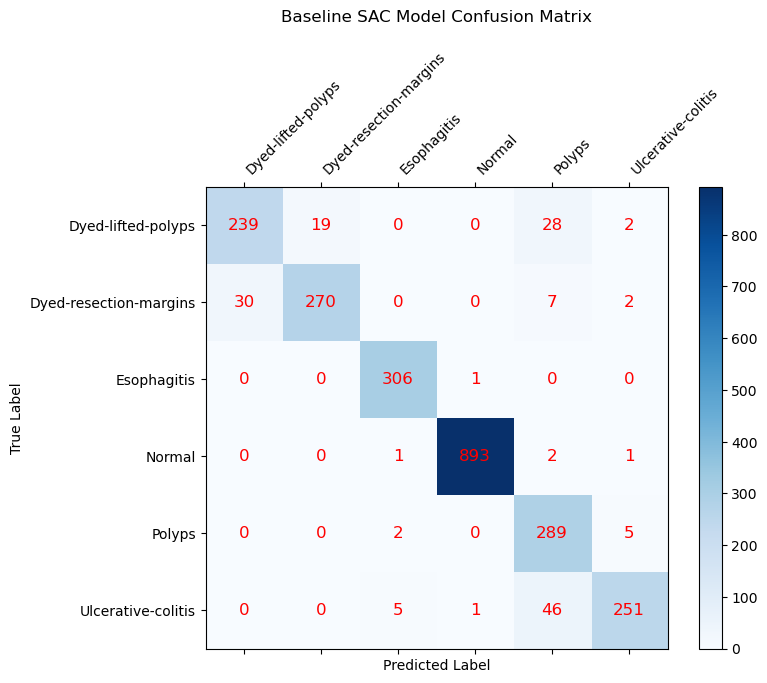

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

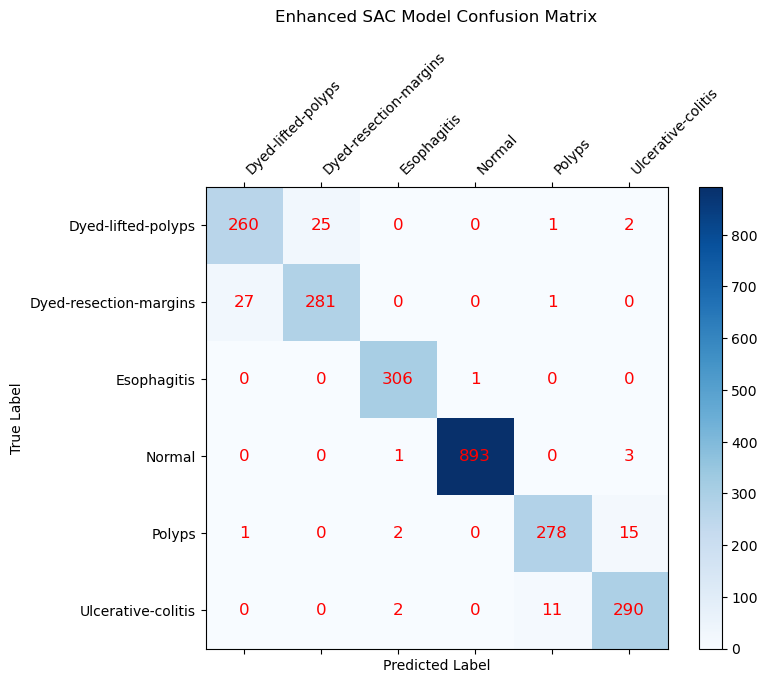

In [6]:
# ===========================================================
# 8. EXPERIMENTS
# ===========================================================
# Experiment A: Baseline Pipeline (Without advanced enhancement)
print("\n=== Training SAC Model with Baseline Preprocessing ===")
model_baseline = build_model(num_classes)
history_baseline = compile_and_train(model_baseline, baseline_train_ds, baseline_val_ds, "SAC_baseline", epochs=25, lr=0.001)
print("\n=== Baseline SAC Model Evaluation ===")
baseline_loss, baseline_val_acc = model_baseline.evaluate(baseline_val_ds, verbose=1)
print(f"Baseline SAC Val Loss: {baseline_loss:.4f} | Baseline SAC Val Accuracy: {baseline_val_acc:.4f}")
evaluate_model(model_baseline, baseline_val_ds, class_names)
plot_training_curves(history_baseline, title_prefix="Baseline SAC Model")

# Experiment B: Enhanced Pipeline (Using CLAHE-only enhancement with tuned parameters)
print("\n=== Training SAC Model with Enhanced Preprocessing ===")
model_enhanced = build_model(num_classes)
# Use a slightly lower learning rate and more epochs for the enhanced pipeline.
history_enhanced = compile_and_train(model_enhanced, enhanced_train_ds, enhanced_val_ds, "SAC_enhanced", epochs=30, lr=0.0008)
print("\n=== Enhanced SAC Model Evaluation ===")
enhanced_loss, enhanced_val_acc = model_enhanced.evaluate(enhanced_val_ds, verbose=1)
print(f"Enhanced SAC Val Loss: {enhanced_loss:.4f} | Enhanced SAC Val Accuracy: {enhanced_val_acc:.4f}")
evaluate_model(model_enhanced, enhanced_val_ds, class_names)
plot_training_curves(history_enhanced, title_prefix="Enhanced SAC Model")

# Plot confusion matrices for both models.
# Baseline:
y_true_b, y_pred_b = [], []
for images, labels in baseline_val_ds:
    preds = model_baseline.predict(images)
    y_true_b.extend(labels.numpy())
    y_pred_b.extend(np.argmax(preds, axis=1))
cm_baseline = confusion_matrix(y_true_b, y_pred_b)
print("\nBaseline SAC Model Confusion Matrix:")
plot_confusion_matrix(cm_baseline, class_names, title="Baseline SAC Model Confusion Matrix")

# Enhanced:
y_true_e, y_pred_e = [], []
for images, labels in enhanced_val_ds:
    preds = model_enhanced.predict(images)
    y_true_e.extend(labels.numpy())
    y_pred_e.extend(np.argmax(preds, axis=1))
cm_enhanced = confusion_matrix(y_true_e, y_pred_e)
print("\nEnhanced SAC Model Confusion Matrix:")
plot_confusion_matrix(cm_enhanced, class_names, title="Enhanced SAC Model Confusion Matrix")


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, 
                             recall_score, f1_score, roc_auc_score)
import tensorflow as tf

def compute_metrics(model, dataset, class_names, model_name):
    # Gather predictions and true labels.
    y_true = []
    y_pred = []
    y_pred_prob = []
    for images, labels in dataset:
        preds = model.predict(images)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(preds, axis=1))
        y_pred_prob.extend(preds)
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_pred_prob = np.array(y_pred_prob)
    
    # Calculate standard metrics.
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted')
    rec = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    cm = confusion_matrix(y_true, y_pred)
    
    # Compute sensitivity and specificity per class.
    sensitivity = {}
    specificity = {}
    total = np.sum(cm)
    for i in range(len(class_names)):
        TP = cm[i, i]
        FN = np.sum(cm[i, :]) - TP
        FP = np.sum(cm[:, i]) - TP
        TN = total - TP - FN - FP
        sensitivity[class_names[i]] = TP / (TP + FN) if (TP + FN) != 0 else 0
        specificity[class_names[i]] = TN / (TN + FP) if (TN + FP) != 0 else 0

    # Compute ROC AUC per class (one-vs-rest).
    y_true_onehot = tf.keras.utils.to_categorical(y_true, len(class_names))
    roc_auc = {}
    for i, cls in enumerate(class_names):
        try:
            auc = roc_auc_score(y_true_onehot[:, i], y_pred_prob[:, i])
        except Exception as e:
            auc = None
        roc_auc[cls] = auc

    # Print metrics.
    print(f"--- {model_name} Evaluation Metrics ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print("Sensitivity per class:", sensitivity)
    print("Specificity per class:", specificity)
    print("ROC AUC per class:", roc_auc)
    print("Confusion Matrix:\n", cm)
    
    return {
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "roc_auc": roc_auc,
        "confusion_matrix": cm
    }

def plot_training_validation_metrics(history, model_name):
    epochs = range(1, len(history.history['accuracy']) + 1)
    
    # Plot training metrics: accuracy and loss on the same figure.
    fig, ax1 = plt.subplots()
    ax1.plot(epochs, history.history['accuracy'], 'g-', label='Training Accuracy')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Accuracy', color='g')
    ax2 = ax1.twinx()
    ax2.plot(epochs, history.history['loss'], 'b-', label='Training Loss')
    ax2.set_ylabel('Loss', color='b')
    plt.title(f"{model_name} Training Metrics")
    fig.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15))
    plt.savefig(f"{model_name}_training_metrics.jpeg", format="jpeg")
    plt.close(fig)
    
    # Plot validation metrics: accuracy and loss on the same figure.
    fig, ax1 = plt.subplots()
    ax1.plot(epochs, history.history['val_accuracy'], 'g-', label='Validation Accuracy')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Validation Accuracy', color='g')
    ax2 = ax1.twinx()
    ax2.plot(epochs, history.history['val_loss'], 'b-', label='Validation Loss')
    ax2.set_ylabel('Validation Loss', color='b')
    plt.title(f"{model_name} Validation Metrics")
    fig.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15))
    plt.savefig(f"{model_name}_validation_metrics.jpeg", format="jpeg")
    plt.close(fig)

# Example usage for the baseline model:
baseline_metrics = compute_metrics(model_baseline, baseline_val_ds, class_names, "SAC_baseline")
plot_training_validation_metrics(history_baseline, "SAC_baseline")

# Example usage for the enhanced model:
enhanced_metrics = compute_metrics(model_enhanced, enhanced_val_ds, class_names, "SAC_enhanced")
plot_training_validation_metrics(history_enhanced, "SAC_enhanced")

# Optionally, save the full models if not already saved.
model_baseline.save("SAC_baseline_full.h5")
model_enhanced.save("SAC_enhanced_full.h5")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

Baseline Model Training Accuracy: 0.9992858171463013
Baseline Model Validation Accuracy: 0.9366666674613953
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/

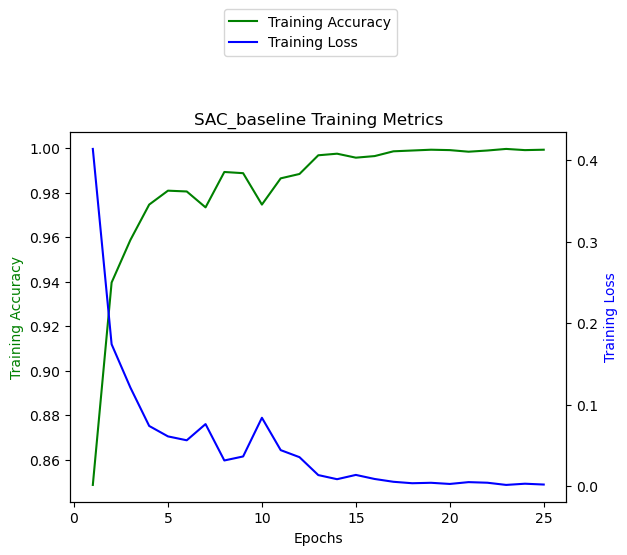

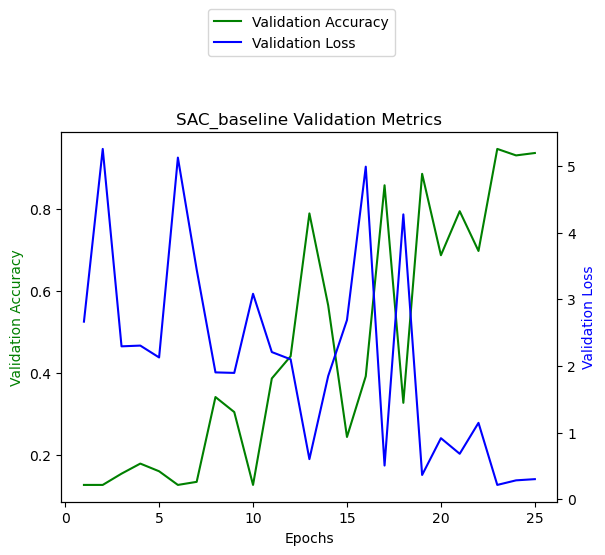

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

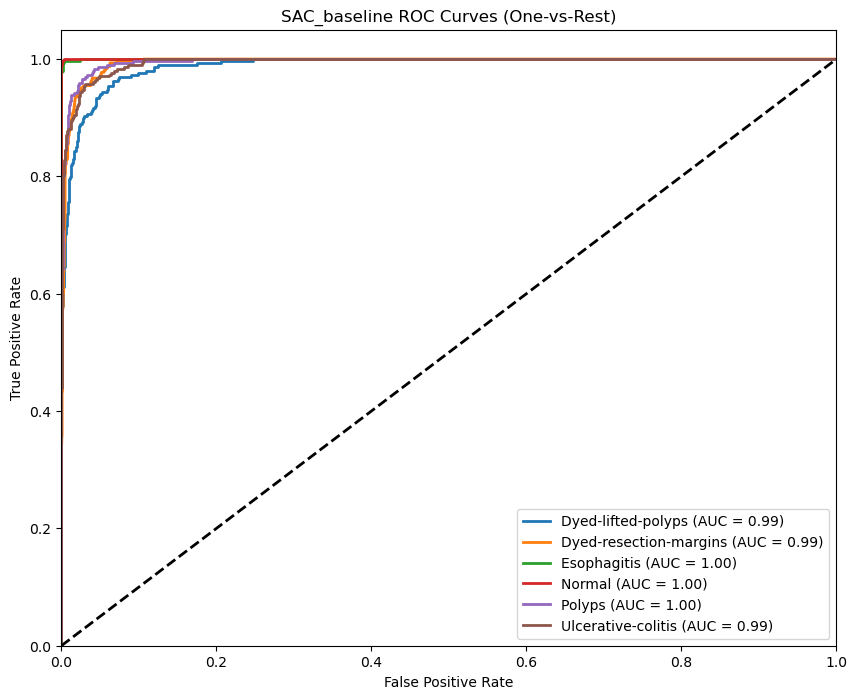

Enhanced Model Training Accuracy: 0.9994643926620483
Enhanced Model Validation Accuracy: 0.9629166722297668
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/

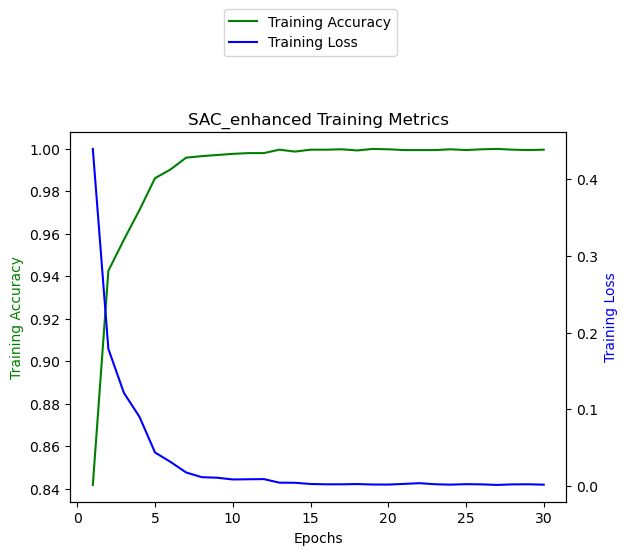

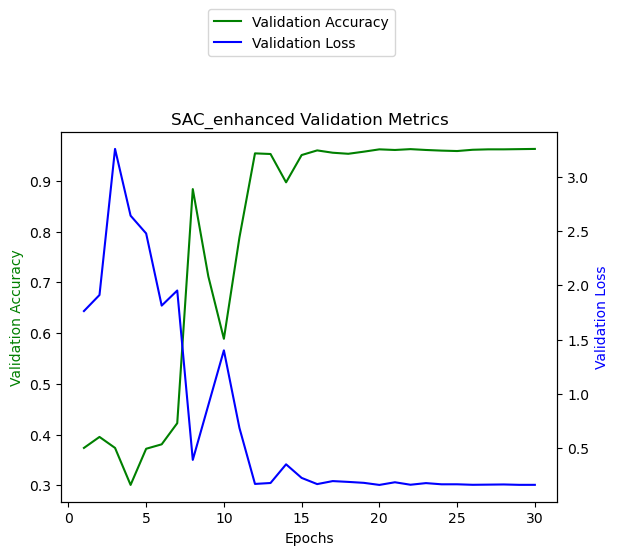

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

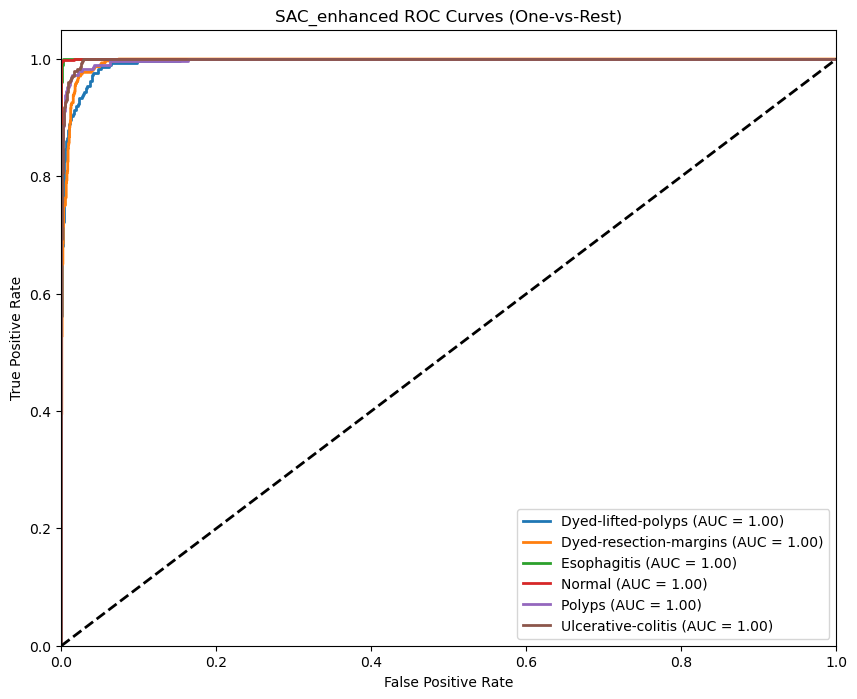

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, 
                             recall_score, f1_score, roc_curve, auc, roc_auc_score)

# -------------------------------
# Function: Compute Evaluation Metrics
# -------------------------------
def compute_metrics(model, dataset, class_names, model_name):
    # Collect predictions and labels.
    y_true, y_pred, y_pred_prob = [], [], []
    for images, labels in dataset:
        preds = model.predict(images)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(preds, axis=1))
        y_pred_prob.extend(preds)
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_pred_prob = np.array(y_pred_prob)
    
    # Standard metrics.
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted')
    rec = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    cm = confusion_matrix(y_true, y_pred)
    
    # Compute sensitivity and specificity per class.
    sensitivity = {}
    specificity = {}
    total = np.sum(cm)
    for i in range(len(class_names)):
        TP = cm[i, i]
        FN = np.sum(cm[i, :]) - TP
        FP = np.sum(cm[:, i]) - TP
        TN = total - TP - FN - FP
        sensitivity[class_names[i]] = TP / (TP + FN) if (TP + FN) > 0 else 0
        specificity[class_names[i]] = TN / (TN + FP) if (TN + FP) > 0 else 0
        
    # Compute ROC AUC per class (one-vs-rest).
    y_true_onehot = tf.keras.utils.to_categorical(y_true, len(class_names))
    roc_auc = {}
    for i, cls in enumerate(class_names):
        try:
            auc_val = roc_auc_score(y_true_onehot[:, i], y_pred_prob[:, i])
        except Exception as e:
            auc_val = None
        roc_auc[cls] = auc_val

    print(f"\n--- {model_name} Evaluation Metrics ---")
    print(f"Overall Accuracy:  {acc:.4f}")
    print(f"Precision:       {prec:.4f}")
    print(f"Recall:          {rec:.4f}")
    print(f"F1 Score:        {f1:.4f}")
    print("Sensitivity per class:", sensitivity)
    print("Specificity per class:", specificity)
    print("ROC AUC per class:", roc_auc)
    print("Confusion Matrix:\n", cm)
    
    return {
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "roc_auc": roc_auc,
        "confusion_matrix": cm
    }

# -------------------------------
# Function: Plot Training & Validation Metrics
# -------------------------------
def plot_training_validation_metrics(history, model_name):
    epochs = range(1, len(history.history['accuracy']) + 1)
    
    # Plot Training Accuracy and Loss.
    fig, ax1 = plt.subplots()
    ax1.plot(epochs, history.history['accuracy'], 'g-', label='Training Accuracy')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Training Accuracy', color='g')
    ax2 = ax1.twinx()
    ax2.plot(epochs, history.history['loss'], 'b-', label='Training Loss')
    ax2.set_ylabel('Training Loss', color='b')
    plt.title(f"{model_name} Training Metrics")
    fig.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15))
    plt.savefig(f"{model_name}_training_metrics.jpeg", format='jpeg')
    plt.show()
    plt.close(fig)
    
    # Plot Validation Accuracy and Loss.
    fig, ax1 = plt.subplots()
    ax1.plot(epochs, history.history['val_accuracy'], 'g-', label='Validation Accuracy')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Validation Accuracy', color='g')
    ax2 = ax1.twinx()
    ax2.plot(epochs, history.history['val_loss'], 'b-', label='Validation Loss')
    ax2.set_ylabel('Validation Loss', color='b')
    plt.title(f"{model_name} Validation Metrics")
    fig.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15))
    plt.savefig(f"{model_name}_validation_metrics.jpeg", format='jpeg')
    plt.show()
    plt.close(fig)

# -------------------------------
# Function: Plot ROC Curves (One-vs-Rest for Each Class)
# -------------------------------
def plot_roc_curves(model, dataset, class_names, model_name):
    y_true, y_pred_prob = [], []
    for images, labels in dataset:
        preds = model.predict(images)
        y_true.extend(labels.numpy())
        y_pred_prob.extend(preds)
    y_true = np.array(y_true)
    y_pred_prob = np.array(y_pred_prob)
    y_true_onehot = tf.keras.utils.to_categorical(y_true, len(class_names))
    
    plt.figure(figsize=(10, 8))
    for i, cls in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_true_onehot[:, i], y_pred_prob[:, i])
        roc_auc_val = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'{cls} (AUC = {roc_auc_val:.2f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{model_name} ROC Curves (One-vs-Rest)')
    plt.legend(loc='lower right')
    plt.savefig(f'{model_name}_roc_curves.jpeg', format='jpeg')
    plt.show()
    plt.close()

# -------------------------------
# Combined Evaluation for Baseline Model
# -------------------------------
print("Baseline Model Training Accuracy:", history_baseline.history['accuracy'][-1])
print("Baseline Model Validation Accuracy:", history_baseline.history['val_accuracy'][-1])
baseline_metrics = compute_metrics(model_baseline, baseline_val_ds, class_names, "SAC_baseline")
plot_training_validation_metrics(history_baseline, "SAC_baseline")
plot_roc_curves(model_baseline, baseline_val_ds, class_names, "SAC_baseline")

# -------------------------------
# Combined Evaluation for Enhanced Model
# -------------------------------
print("Enhanced Model Training Accuracy:", history_enhanced.history['accuracy'][-1])
print("Enhanced Model Validation Accuracy:", history_enhanced.history['val_accuracy'][-1])
enhanced_metrics = compute_metrics(model_enhanced, enhanced_val_ds, class_names, "SAC_enhanced")
plot_training_validation_metrics(history_enhanced, "SAC_enhanced")
plot_roc_curves(model_enhanced, enhanced_val_ds, class_names, "SAC_enhanced")
